# Bookings Forecast & Member Health
**Client:** a UK contrast-therapy studio and café · **Data:** booking system transactions, 1 Jan – 28 Apr 2026, plus café till reports

## At a glance
- **Forecast:** about **200 sessions a week** for the next 8 weeks (29 Apr – 23 Jun 2026), 80% range roughly 150–250 a week. Demand is flat: no growth or decline once day of week is accounted for.
- **Why trust it:** forecast April using only January–March. The chosen model (Poisson regression on day of week + trend) had the lowest weekly error of five methods (4.5%), and 22 of 28 April days landed inside its 80% range.
- **Money left on the table:** £2,249 of failed membership payments from 9 members were never recovered, and failed attempts are rising every month.
- **Retention:** 64% of pay-as-you-go customers visited once and never came back; the 30-day return rate fell from 35% (January newcomers) to 19% (March).
- **Staffing:** weekends are 4× busier than Tuesdays; the midday block Friday–Sunday is the peak.

These figures match the client pack (PDF) and the weekly tracker (Excel).

## 1. Data and privacy
The booking export contained customer names and emails. Before any analysis it was pseudonymised on the client's machine: each customer became an ID (`M-0001`, …), and names, emails, staff names and payment IDs were dropped. Nothing in this notebook can identify a person. Service and product names were also de-branded so the business isn't identifiable.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, BAND, GREY = "#2a78d6", "#eb6834", "#cde2fb", "#a3a29c"

DATA_DIR = "../data/"   # data not included: client data, shared with permission
d = pd.read_csv(DATA_DIR + "transactions_anon.csv")
d["ts"] = pd.to_datetime(d["date"] + " " + d["time"], dayfirst=True)
d["day"] = d.ts.dt.normalize()
for c in ["amount_gbp", "failed_amount_gbp"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")
print(f"{len(d):,} transactions, {d.member_id.nunique():,} customer IDs, {d.ts.min():%d %b} to {d.ts.max():%d %b %Y}")
d.status.value_counts()

3,993 transactions, 905 customer IDs, 01 Jan to 28 Apr 2026


status
PAID              3832
FAILED             131
REFUNDED            20
PENDING_INTENT      10
Name: count, dtype: int64

## 2. What counts as a session
Sessions are paid or complimentary bookings for contrast therapy (peak and off-peak), hyperbaric oxygen, breathwork and women-only sessions. Failed, refunded and pending bookings are excluded.

Six accounts average more than one session a day. These are shared or house accounts (staff, front desk, members logged under one account), so they stay in the demand forecast but are left out of customer-level analysis.

In [2]:
PAT = r"Contrast Therapy$|Contrast Therapy Off-Peak$|HBOT \(|Breathwork x|Women"
sess = d[d.service.str.contains(PAT, regex=True) & (d.status == "PAID")].copy()
END = pd.Timestamp("2026-04-28")
daily = sess.groupby("day").size().reindex(pd.date_range("2026-01-01", END), fill_value=0).astype(float)

vc = sess.member_id.value_counts()
HOUSE = list(vc[vc >= 119].index)   # more than 1 session a day on average
print(f"{len(sess):,} sessions; {len(HOUSE)} shared accounts hold {sess.member_id.isin(HOUSE).sum():,} of them "
      f"({sess.member_id.isin(HOUSE).mean():.0%})")
sess.service.value_counts()

3,380 sessions; 6 shared accounts hold 1,777 of them (53%)


service
Contrast Therapy                            2506
Contrast Therapy Off-Peak                    722
HBOT (Hyperbaric Oxygen Therapy)              72
Breathwork x Contrast (guest instructor)      64
Women’s Only Contrast Therapy                 16
Name: count, dtype: int64

## 3. Demand patterns

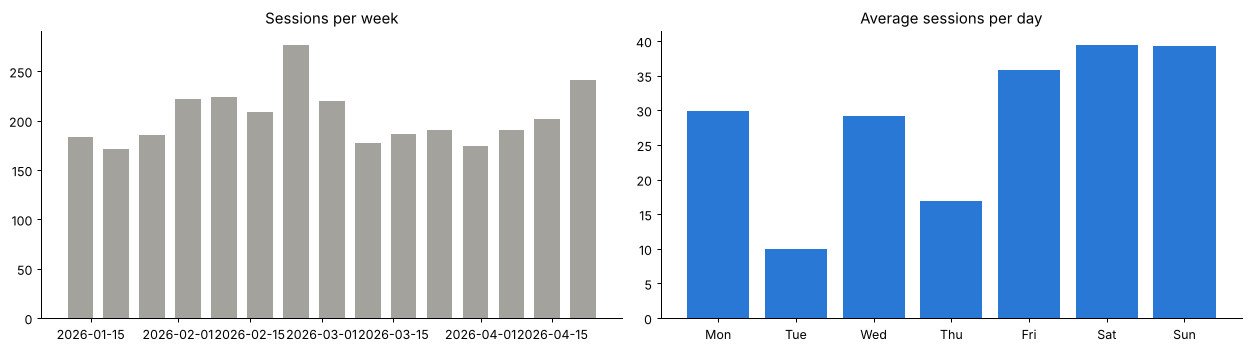

Mon    29.9
Tue     9.9
Wed    29.2
Thu    16.9
Fri    35.8
Sat    39.5
Sun    39.3
dtype: float64

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
wk = daily.resample("W-TUE").sum()[1:-1]
ax[0].bar(wk.index, wk.values, width=5, color=GREY); ax[0].set_title("Sessions per week")
dow = daily.groupby(daily.index.dayofweek).mean()
ax[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow.values, color=BLUE); ax[1].set_title("Average sessions per day")
plt.tight_layout(); plt.show()
dow.round(1).set_axis(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])

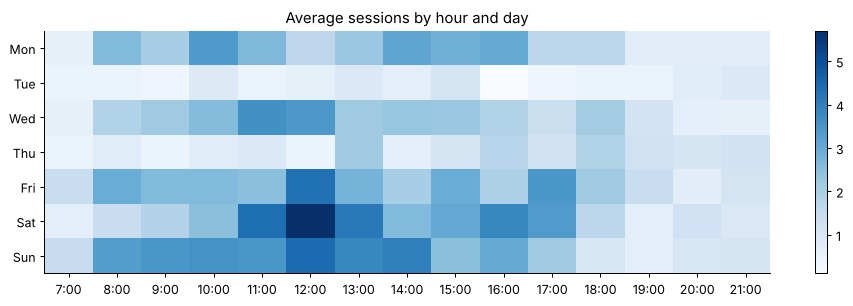

In [4]:
sess["dow"], sess["hr"] = sess.ts.dt.dayofweek, sess.ts.dt.hour
ndays = daily.groupby(daily.index.dayofweek).size()
heat = sess.groupby(["dow", "hr"]).size().unstack(fill_value=0).div(ndays, axis=0).reindex(columns=range(7, 22), fill_value=0)
fig, ax = plt.subplots(figsize=(13, 3.5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(15)); ax.set_xticklabels([f"{h}:00" for h in range(7, 22)])
ax.set_title("Average sessions by hour and day"); plt.colorbar(im); plt.show()

## 4. The model
Daily sessions are counts, so the model is a **Poisson regression** with a dummy for each day of the week plus a linear trend. For ranges, 5,000 futures are simulated: each day is drawn from a negative binomial (counts vary more than Poisson allows; alpha = 0.1 was set so ~80% of April days fall inside the 80% range), times a weekly shock sized from how much real weeks varied around the model.

In [5]:
t0 = daily.index[0]
def X_(idx):
    X = pd.get_dummies(idx.dayofweek).astype(float); X.columns = [f"d{c}" for c in X.columns]
    X["t"] = (idx - t0).days / 100; X.index = idx; return X
def fit(train):
    return sm.GLM(train, X_(train.index), family=sm.families.Poisson()).fit()
def weekly_sd(train, m):
    r = (train.resample("W-SUN").sum() / pd.Series(m.predict(X_(train.index)), train.index).resample("W-SUN").sum())[1:-1]
    return float(np.log(r).std())
def simulate(m, idx, alpha, wsd, n=5000, seed=42):
    rng = np.random.default_rng(seed); mu = m.predict(X_(idx)).values
    wk = (idx - idx[0]).days // 7; f = np.exp(rng.normal(0, wsd, (n, wk.max() + 1)))[:, wk]
    r = 1 / alpha; return mu, rng.negative_binomial(r, r / (r + mu * f))
ALPHA = 0.1

## 5. Backtest: forecast April from January–March only

In [6]:
tr, te = daily[:"2026-03-31"], daily["2026-04-01":]; h = len(te)
mb = fit(tr); mu_b, s_b = simulate(mb, te.index, ALPHA, weekly_sd(tr, mb))
methods = {
    "Same weekday last week": np.tile(tr[-7:].values, 5)[:h],
    "Weekday average, last 4 weeks": np.array([tr[-28:][tr[-28:].index.dayofweek == x.dayofweek].mean() for x in te.index]),
    "Seasonal smoothing (ETS)": ExponentialSmoothing(tr, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit().forecast(h).values,
    "Seasonal ARIMA": SARIMAX(tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False).forecast(h).values,
    "Weekday + trend model": mu_b}
wk_te = te.resample("W-SUN").sum(); rows = []
for k, v in methods.items():
    v = np.clip(v, 0, None); wkf = pd.Series(v, te.index).resample("W-SUN").sum()
    rows.append({"Method": k, "Daily MAE": np.mean(np.abs(te.values - v)),
                 "Weekly error": np.abs(wk_te - wkf).sum() / te.sum(), "April total error": v.sum() / te.sum() - 1})
bt = pd.DataFrame(rows).set_index("Method").sort_values("Weekly error")
bt.style.format({"Daily MAE": "{:.1f}", "Weekly error": "{:.1%}", "April total error": "{:+.1%}"})

,Daily MAE,Weekly error,April total error
Method,,,
Weekday + trend model,9.8,4.5%,+1.5%
Seasonal ARIMA,10.0,7.0%,-1.3%
"Weekday average, last 4 weeks",9.5,9.3%,-8.2%
Seasonal smoothing (ETS),9.7,9.5%,-6.9%
Same weekday last week,9.1,14.4%,-12.3%


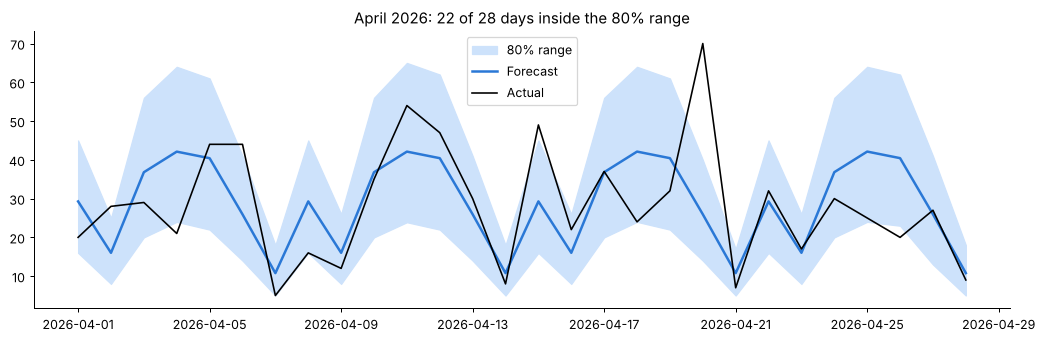

In [7]:
lo, hi = np.percentile(s_b, 10, 0), np.percentile(s_b, 90, 0)
inside = ((te.values >= lo) & (te.values <= hi)).sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(te.index, lo, hi, color=BAND, label="80% range")
ax.plot(te.index, mu_b, color=BLUE, lw=2, label="Forecast"); ax.plot(te.index, te.values, color="k", lw=1.3, label="Actual")
ax.set_title(f"April 2026: {inside} of {h} days inside the 80% range"); ax.legend(); plt.show()

## 6. Forecast: 29 April – 23 June 2026

In [8]:
m = fit(daily); wsd = weekly_sd(daily, m); idx = pd.date_range("2026-04-29", "2026-06-23")
mu, s = simulate(m, idx, ALPHA, wsd)
print(f"Trend: {np.exp(m.params['t']) - 1:+.1%} per 100 days (flat)")
S = pd.DataFrame(s.T, idx)
weeks = pd.DataFrame([{"Week starting": idx[k*7].date(), "Low (P10)": np.percentile(S.iloc[k*7:(k+1)*7].sum(), 10),
                       "Likely": np.median(S.iloc[k*7:(k+1)*7].sum()), "High (P90)": np.percentile(S.iloc[k*7:(k+1)*7].sum(), 90)}
                      for k in range(8)]).set_index("Week starting")
tot = np.percentile(s.sum(1), [10, 50, 90])
print(f"8-week total: likely {tot[1]:,.0f} (80% range {tot[0]:,.0f}–{tot[2]:,.0f})")
weeks.round(0).astype(int)

Trend: -1.6% per 100 days (flat)
8-week total: likely 1,595 (80% range 1,457–1,744)


,Low (P10),Likely,High (P90)
Week starting,,,
2026-04-29,152,197,252
2026-05-06,155,198,254
2026-05-13,152,197,253
2026-05-20,152,196,250
2026-05-27,151,196,252
2026-06-03,153,197,251
2026-06-10,151,195,250
2026-06-17,150,197,252


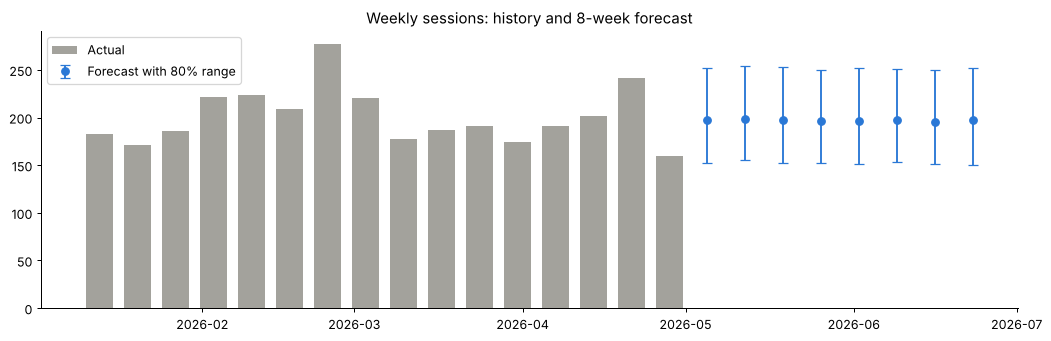

In [9]:
hist = daily.resample("W-TUE").sum()[1:]
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(hist.index, hist.values, width=5, color=GREY, label="Actual")
wkend = [pd.Timestamp(w) + pd.Timedelta(days=6) for w in weeks.index]
ax.errorbar(wkend, weeks["Likely"], yerr=[weeks["Likely"] - weeks["Low (P10)"], weeks["High (P90)"] - weeks["Likely"]],
            fmt="o", color=BLUE, capsize=4, label="Forecast with 80% range")
ax.set_title("Weekly sessions: history and 8-week forecast"); ax.legend(); plt.show()

## 7. Memberships and failed payments

In [10]:
memb = d[d.service.str.contains("Membership")]
pm = memb[(memb.status == "PAID") & (memb.amount_gbp > 0)]
f = memb[memb.status == "FAILED"]
# a failed charge counts as recovered if the same member paid within 14 days
rec = f.apply(lambda r: ((memb.member_id == r.member_id) & (memb.status == "PAID") & (memb.amount_gbp > 0) &
                         (memb.ts > r.ts) & (memb.ts <= r.ts + pd.Timedelta(days=14))).any(), axis=1)
u = f[~rec]
print(f"{len(f)} failed charges (£{f.failed_amount_gbp.sum():,.0f} attempted); {rec.sum()} recovered within 14 days; "
      f"{len(u)} never recovered = £{u.failed_amount_gbp.sum():,.0f} from {u.member_id.nunique()} members")
pd.DataFrame({"Paying members": pm.groupby(pm.ts.dt.month).member_id.nunique(),
              "Membership income (£)": pm.groupby(pm.ts.dt.month).amount_gbp.sum().round(),
              "Failed attempts (£)": f.groupby(f.ts.dt.month).failed_amount_gbp.sum().round()}).rename_axis("Month")

120 failed charges (£6,043 attempted); 73 recovered within 14 days; 47 never recovered = £2,249 from 9 members


,Paying members,Membership income (£),Failed attempts (£)
Month,,,
1,86,3790.0,578.0
2,102,4655.0,992.0
3,116,5405.0,1794.0
4,116,5613.0,2679.0


## 8. Pay-as-you-go customers: segments and return rates

In [11]:
c = sess[~sess.member_id.isin(HOUSE)]
g = c.groupby("member_id").agg(visits=("ts", "size"), first=("ts", "min"), last=("ts", "max"))
g["member"] = g.index.isin(set(pm.member_id))
g["days_since"] = (END - g["last"].dt.normalize()).dt.days
g["days_since_first"] = (END - g["first"].dt.normalize()).dt.days
def seg(r):
    if r.member and r.days_since <= 30: return "Occasional, recent"   # the few active plan holders with own accounts
    if r.days_since_first <= 30: return "New (first 30 days)"
    if r.visits >= 3 and r.days_since <= 30: return "Regular pay-as-you-go"
    if r.visits == 1: return "One visit, not back"
    if r.days_since > 30: return "Lapsed (2+ visits)"
    return "Occasional, recent"
g["segment"] = g.apply(seg, axis=1)
print(f"{len(g)} customers with their own account; {(g.visits == 1).mean():.0%} visited once")
g.groupby("segment").agg(people=("visits", "size"), avg_visits=("visits", "mean")).sort_values("people", ascending=False).round(1)

786 customers with their own account; 64% visited once


,people,avg_visits
segment,,
"One visit, not back",360,1.0
New (first 30 days),167,1.2
Lapsed (2+ visits),147,2.8
Regular pay-as-you-go,77,7.3
"Occasional, recent",35,1.9


In [12]:
gap = c.sort_values("ts").groupby("member_id").ts.apply(lambda x: (x.iloc[1] - x.iloc[0]).days if len(x) > 1 else np.nan)
g["gap"] = gap; g["cohort"] = g["first"].dt.month
coh = g[g.cohort <= 3].groupby("cohort").agg(new=("visits", "size"), back_30d=("gap", lambda x: (x <= 30).mean()))
coh.index = ["Jan", "Feb", "Mar"]; coh.style.format({"back_30d": "{:.0%}"})

,new,back_30d
Jan,268,35%
Feb,204,29%
Mar,166,19%


## 9. Café

cat
Drinks                    14620.0
Sessions sold at till     12571.0
Other / misc               4243.0
Retail (merch & beans)     3483.0
Food                       2696.0


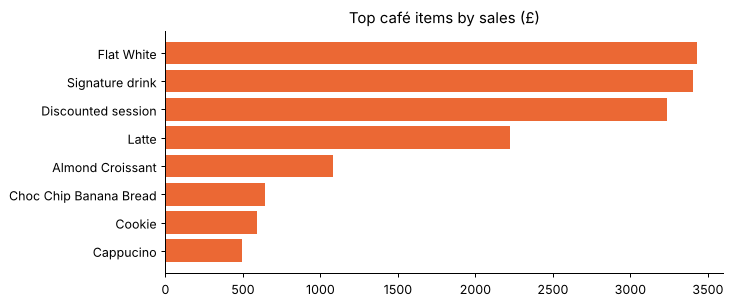

In [13]:
cp = pd.read_csv(DATA_DIR + "cafe_product_totals.csv", encoding="utf-8-sig")
cp = cp[cp.Name.notna() & (cp.Name != "Total:")]; cp["Value"] = pd.to_numeric(cp.Value)
def cat(n):
    n = str(n)
    if any(x in n for x in ["Session", "Credit", "Breath", "Hyperbaric", "Contrast"]): return "Sessions sold at till"
    if any(x in n for x in ["Hoodie", "T Shirt", "Beans", "Blend"]): return "Retail (merch & beans)"
    if any(x in n for x in ["Croissant", "Bread", "Cookie", "Chocolat"]): return "Food"
    if n in ["Misc", "Mis", "G", "40", "70"]: return "Other / misc"
    return "Drinks"
cp["cat"] = cp.Name.map(cat)
print(cp.groupby("cat").Value.sum().round().sort_values(ascending=False).to_string())
top = cp[cp.cat.isin(["Drinks", "Food"])].nlargest(8, "Value").iloc[::-1]
plt.figure(figsize=(8, 3.5)); plt.barh(top.Name, top.Value, color=ORANGE); plt.title("Top café items by sales (£)"); plt.show()

## 10. Recommendations and next steps
1. **Chase unrecovered failed payments** (£2,249 from 9 members) and switch on automatic retries and card-update reminders.
2. **Win back lapsed and one-visit customers** with a targeted offer; bringing back 1 in 10 is worth about £980 a month at £15 a session.
3. **Follow up every first visit within 2 weeks**: the 30-day return rate is falling.
4. **Fill Tuesdays and Thursdays** with off-peak pricing.
5. **Log member visits on members' own accounts**, so usage and churn can be tracked per person.

**Limitations:** four months of history, so no yearly seasonality (summer and Christmas) is in the model yet. Café figures are product totals with no dates, so café demand can't be forecast until an itemised till export is available. Refresh monthly as data comes in.